# EOF analysis of LMR output

using [this xeof tutorial](https://xeofs.readthedocs.io/en/latest/content/user_guide/auto_examples/1single/plot_eof-tmode.html#sphx-glr-content-user-guide-auto-examples-1single-plot-eof-tmode-py)

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from cartopy.crs import EqualEarth, PlateCarree
from matplotlib.gridspec import GridSpec
import xeofs as xe
import cfr
import numpy as np

## LMRv2.1*

In [4]:
res_lmr = cfr.ReconRes('./recons/lmr_reproduce_pda_ptype_res/')
res_lmr.load(['tas', 'tas_gm'])
lmr_fd = res_lmr.da

tas = lmr_fd['tas'].mean(dim='ens')

In [5]:
eof_lmr = xe.single.EOF(n_modes=4,use_coslat=True)
eof_lmr.fit(tas, dim=("time"))
expvar_lmr = eof_lmr.explained_variance_ratio()
components_lmr = eof_lmr.components()
scores_lmr = eof_lmr.scores()

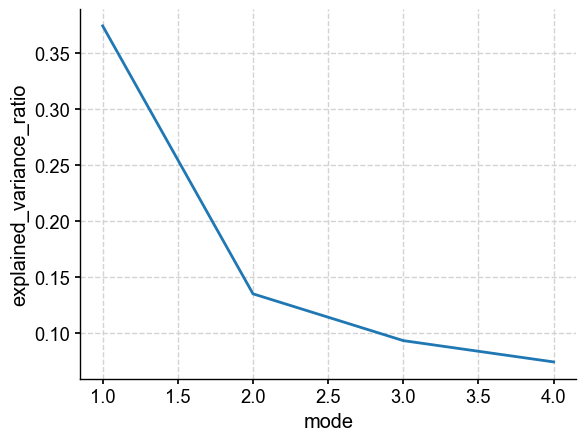

In [6]:
expvar_lmr.plot()

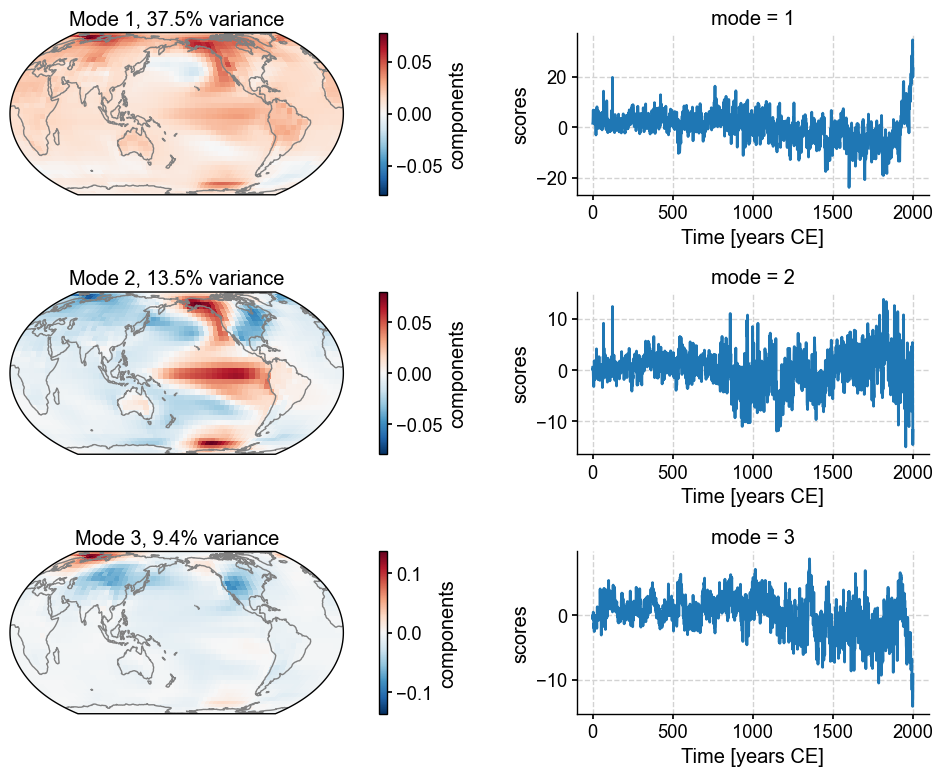

In [7]:
proj = EqualEarth(central_longitude=180)
kwargs = {"cmap": "RdBu_r", "transform": PlateCarree()}
nmodes = 3 
fig = plt.figure(figsize=(12, 8))
gs = GridSpec(nmodes, 2, width_ratios=[2, 1])
ax0 = [fig.add_subplot(gs[i, 0], projection=proj) for i in range(nmodes)]
ax1 = [fig.add_subplot(gs[i, 1]) for i in range(nmodes)]

for i, (a0, a1) in enumerate(zip(ax0, ax1)):
    components_lmr.sel(mode=i+1).plot(ax=a0, **kwargs)
    a0.coastlines(color=".5")
    a0.set_title(f'Mode {i+1}, {100*expvar_lmr[i]:3.1f}% variance')
    a0.set_xlabel("")
    scores_lmr.sel(mode=i + 1).plot(ax=a1)
    a1.set_xlabel("Time [years CE]")

plt.tight_layout()
#fig.savefig("LMRv2.1*_tas_eofs1-3.pdf",dpi=300)

## PReSto2k

In [8]:
res_pc = cfr.ReconRes('./recons/lmr_reproduce_lipd/')
res_pc.load(['tas', 'tas_gm'])
pc_fd = res_pc.da

In [9]:
tas_pc = pc_fd['tas'].mean(dim='ens')

In [10]:
eof_pc = xe.single.EOF(n_modes=4,use_coslat=True)
eof_pc.fit(tas_pc, dim=("time"))
expvar_pc = eof_pc.explained_variance_ratio()
components_pc = eof_pc.components()
scores_pc = eof_pc.scores()

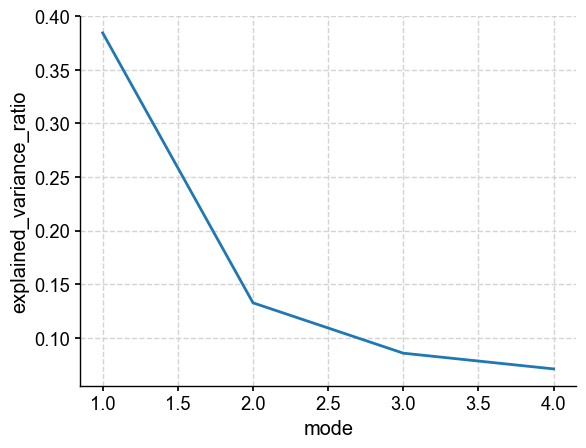

In [11]:
expvar_pc.plot()

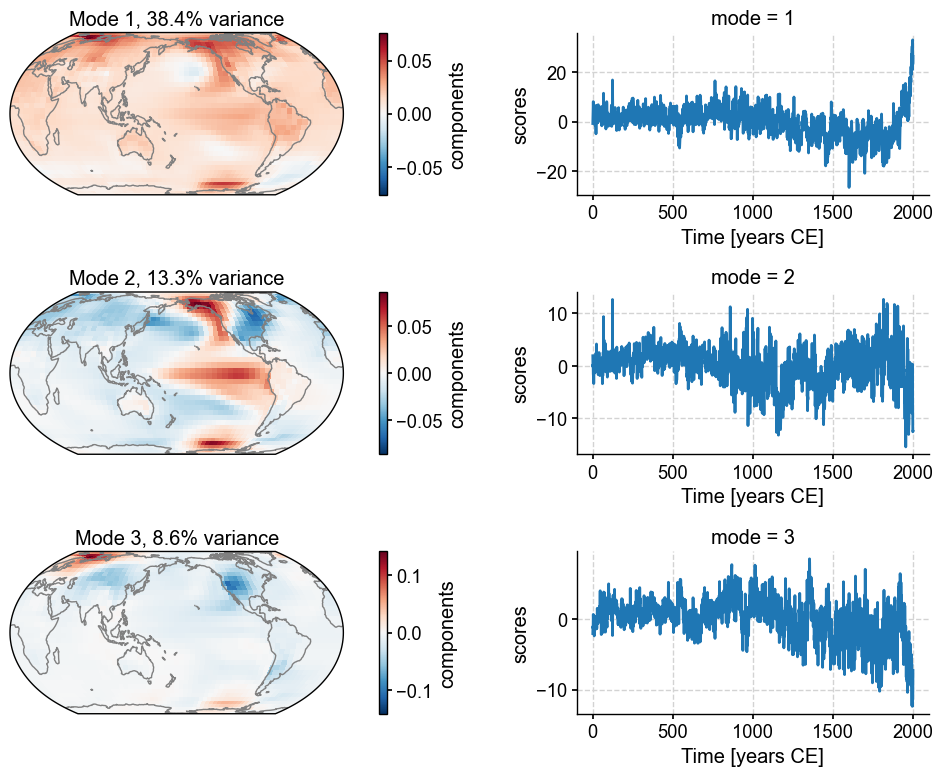

In [12]:
proj = EqualEarth(central_longitude=180)
kwargs = {"cmap": "RdBu_r", "transform": PlateCarree()}
nmodes = 3 
fig = plt.figure(figsize=(12, 8))
gs = GridSpec(nmodes, 2, width_ratios=[2, 1])
ax0 = [fig.add_subplot(gs[i, 0], projection=proj) for i in range(nmodes)]
ax1 = [fig.add_subplot(gs[i, 1]) for i in range(nmodes)]

for i, (a0, a1) in enumerate(zip(ax0, ax1)):
    components_pc.sel(mode=i+1).plot(ax=a0, **kwargs)
    a0.coastlines(color=".5")
    a0.set_title(f'Mode {i+1}, {100*expvar_pc[i]:3.1f}% variance')
    a0.set_xlabel("")
    scores_pc.sel(mode=i + 1).plot(ax=a1)
    a1.set_xlabel("Time [years CE]")

plt.tight_layout()
#fig.savefig("PReSto2k_tas_eofs1-3.pdf",dpi=300)

## PReSto2k-DOCU

In [13]:
res_dp = cfr.ReconRes('./recons/docu_presto/')
res_dp.load(['tas', 'tas_gm'])
dp_fd = res_dp.da

In [14]:
tas_dp = dp_fd['tas'].mean(dim='ens')

In [15]:
eof_dp = xe.single.EOF(n_modes=4,use_coslat=True)
eof_dp.fit(tas_dp, dim=("time"))
expvar_dp = eof_dp.explained_variance_ratio()
components_dp = eof_dp.components()
scores_dp = eof_dp.scores()

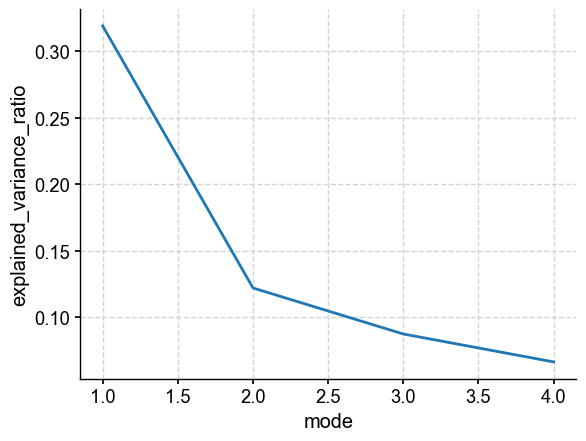

In [16]:
expvar_dp.plot()

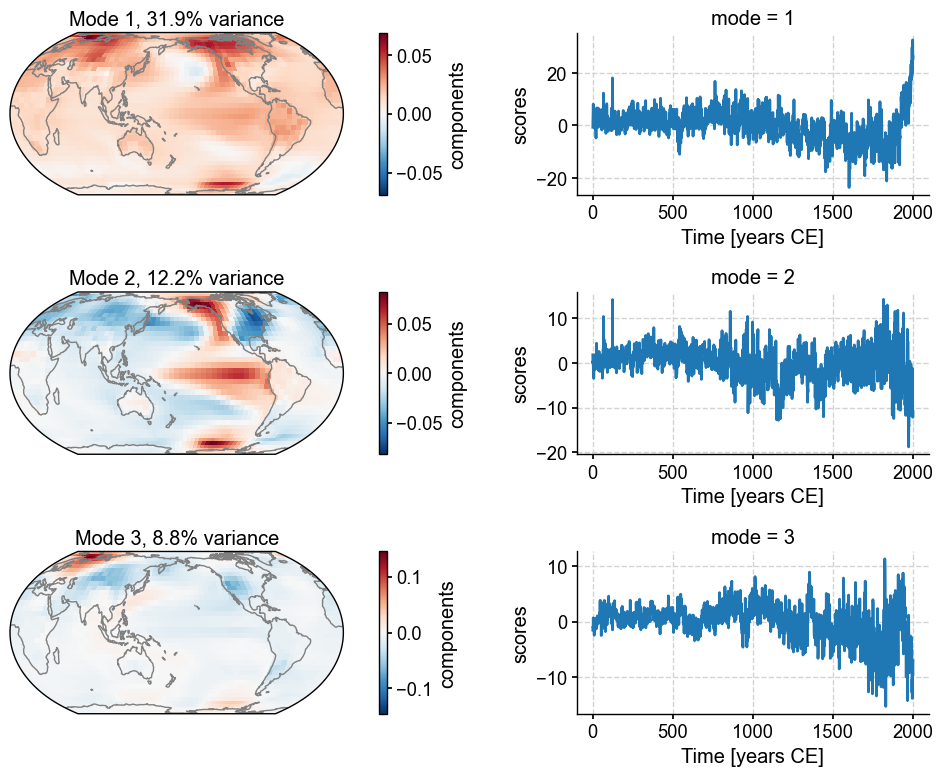

In [17]:
proj = EqualEarth(central_longitude=180)
kwargs = {"cmap": "RdBu_r", "transform": PlateCarree()}
nmodes = 3 
fig = plt.figure(figsize=(12, 8))
gs = GridSpec(nmodes, 2, width_ratios=[2, 1])
ax0 = [fig.add_subplot(gs[i, 0], projection=proj) for i in range(nmodes)]
ax1 = [fig.add_subplot(gs[i, 1]) for i in range(nmodes)]

for i, (a0, a1) in enumerate(zip(ax0, ax1)):
    components_dp.sel(mode=i+1).plot(ax=a0, **kwargs)
    a0.coastlines(color=".5")
    a0.set_title(f'Mode {i+1}, {100*expvar_dp[i]:3.1f}% variance')
    a0.set_xlabel("")
    scores_dp.sel(mode=i + 1).plot(ax=a1)
    a1.set_xlabel("Time [years CE]")

plt.tight_layout()
#fig.savefig("PReSto2k-DOCU_tas_eofs1-3.pdf",dpi=300)

## 1500 analysis

In [ ]:
tas_1500 = tas.sel(time=slice(1500,2000))
tas_dp_1500 = tas_dp.sel(time=slice(1500,2000))

In [ ]:
eof_l15 = xe.single.EOF(n_modes=4,use_coslat=True)
eof_l15.fit(tas_1500, dim=("time"))
expvar_l15 = eof_l15.explained_variance_ratio()
components_l15 = eof_l15.components()
scores_l15 = eof_l15.scores()

In [ ]:
eof_d15 = xe.single.EOF(n_modes=4,use_coslat=True)
eof_d15.fit(tas_dp_1500, dim=("time"))
expvar_d15 = eof_d15.explained_variance_ratio()
components_d15 = eof_d15.components()
scores_d15 = eof_d15.scores()

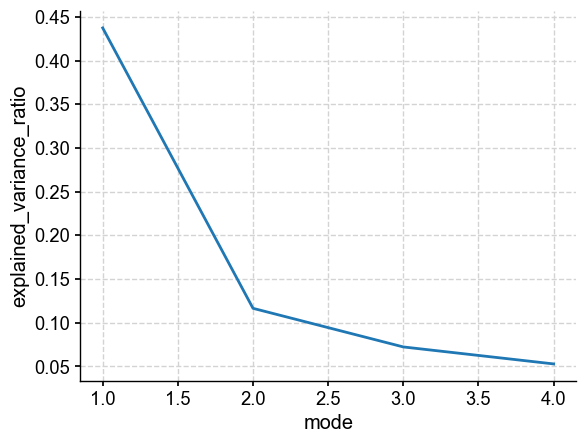

In [ ]:
expvar_l15.plot()

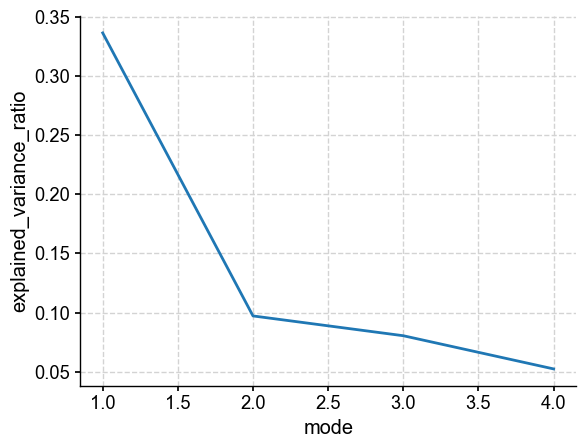

In [ ]:
expvar_d15.plot()

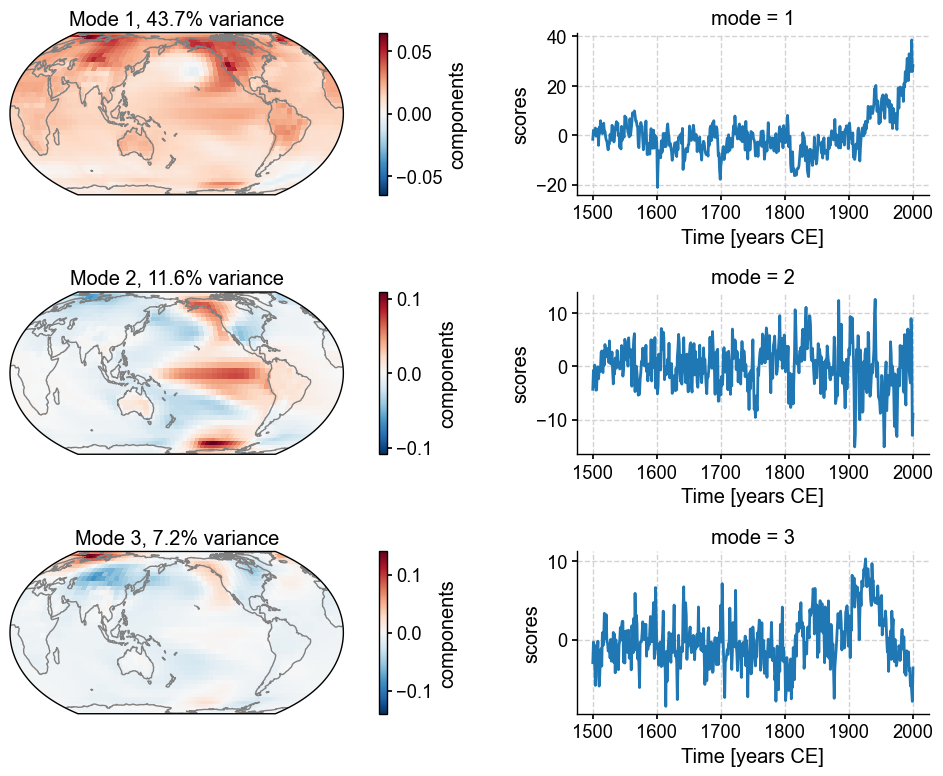

In [ ]:
proj = EqualEarth(central_longitude=180)
kwargs = {"cmap": "RdBu_r", "transform": PlateCarree()}
nmodes = 3 
fig = plt.figure(figsize=(12, 8))
gs = GridSpec(nmodes, 2, width_ratios=[2, 1])
ax0 = [fig.add_subplot(gs[i, 0], projection=proj) for i in range(nmodes)]
ax1 = [fig.add_subplot(gs[i, 1]) for i in range(nmodes)]

for i, (a0, a1) in enumerate(zip(ax0, ax1)):
    components_l15.sel(mode=i+1).plot(ax=a0, **kwargs)
    a0.coastlines(color=".5")
    a0.set_title(f'Mode {i+1}, {100*expvar_l15[i]:3.1f}% variance')
    a0.set_xlabel("")
    scores_l15.sel(mode=i + 1).plot(ax=a1)
    a1.set_xlabel("Time [years CE]")

plt.tight_layout()

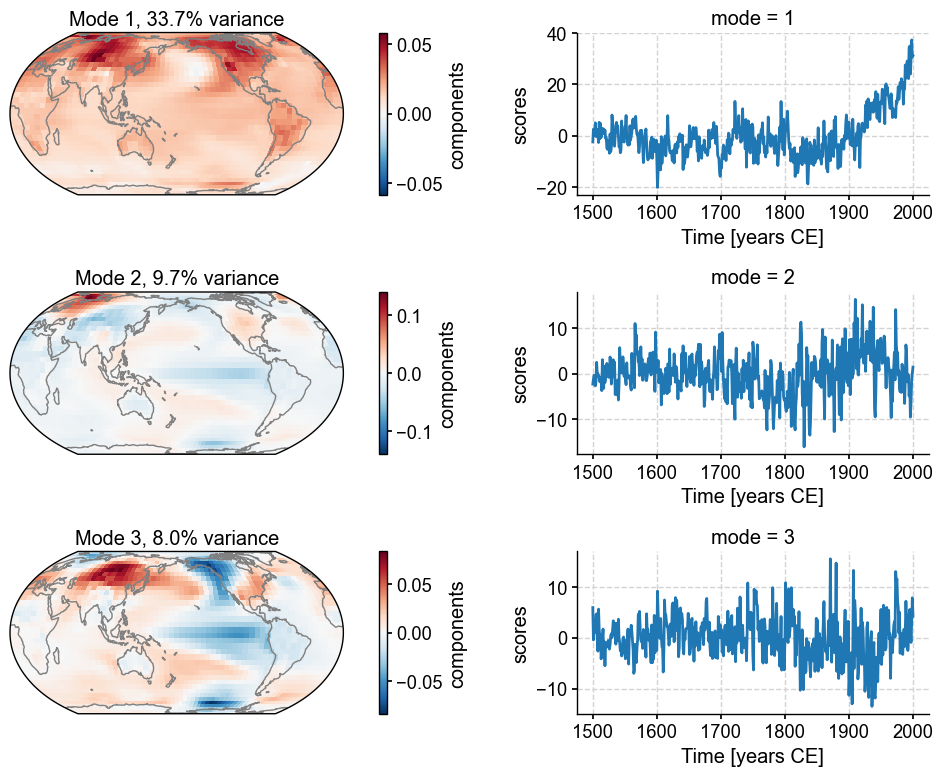

In [ ]:
proj = EqualEarth(central_longitude=180)
kwargs = {"cmap": "RdBu_r", "transform": PlateCarree()}
nmodes = 3 
fig = plt.figure(figsize=(12, 8))
gs = GridSpec(nmodes, 2, width_ratios=[2, 1])
ax0 = [fig.add_subplot(gs[i, 0], projection=proj) for i in range(nmodes)]
ax1 = [fig.add_subplot(gs[i, 1]) for i in range(nmodes)]

for i, (a0, a1) in enumerate(zip(ax0, ax1)):
    components_d15.sel(mode=i+1).plot(ax=a0, **kwargs)
    a0.coastlines(color=".5")
    a0.set_title(f'Mode {i+1}, {100*expvar_d15[i]:3.1f}% variance')
    a0.set_xlabel("")
    scores_d15.sel(mode=i + 1).plot(ax=a1)
    a1.set_xlabel("Time [years CE]")

plt.tight_layout()

In [18]:
def contiguous_intervals(years):
    years = np.sort(years)
    intervals = []
    start = years[0]

    for i in range(1, len(years)):
        if years[i] != years[i-1] + 1:  # break in sequence
            intervals.append((start, years[i-1]))
            start = years[i]
    intervals.append((start, years[-1]))
    return intervals


In [19]:
high_kd_years2 = np.load("high_kd_years_docu.npy")
intervals2 = contiguous_intervals(high_kd_years2)

high_kd_years1 = np.load("high_kd_years_presto.npy")
intervals1 = contiguous_intervals(high_kd_years1)

## COmparisons

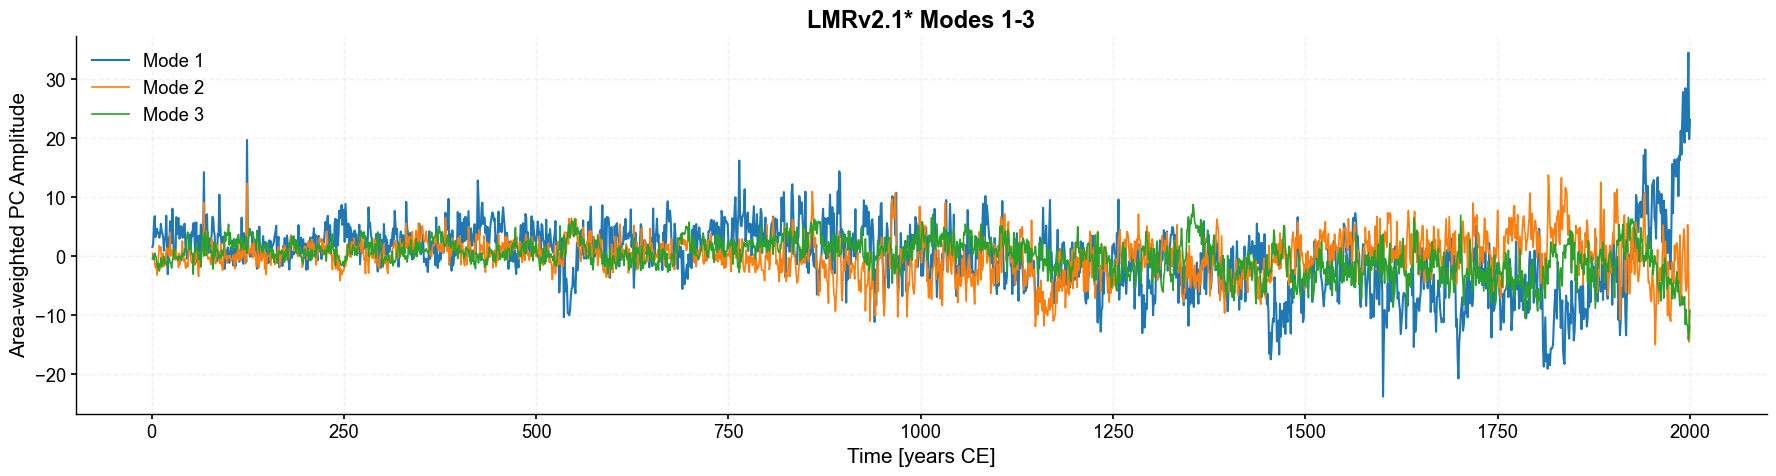

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Compute differences
diff_mode1 = scores_lmr.sel(mode=1)
diff_mode2 = scores_lmr.sel(mode=2)
diff_mode3 = scores_lmr.sel(mode=3)

fig, ax = plt.subplots(figsize=(18, 5))

diff_mode1.plot(ax=ax, label="Mode 1", linewidth=1.5)
diff_mode2.plot(ax=ax, label="Mode 2", linewidth=1.2)
diff_mode3.plot(ax=ax, label="Mode 3", linewidth=1.2)


ax.set_title("LMRv2.1* Modes 1-3", fontsize=17, fontweight='bold')
ax.set_ylabel("Area-weighted PC Amplitude", fontsize=15)
ax.set_xlabel("Time [years CE]", fontsize=15)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

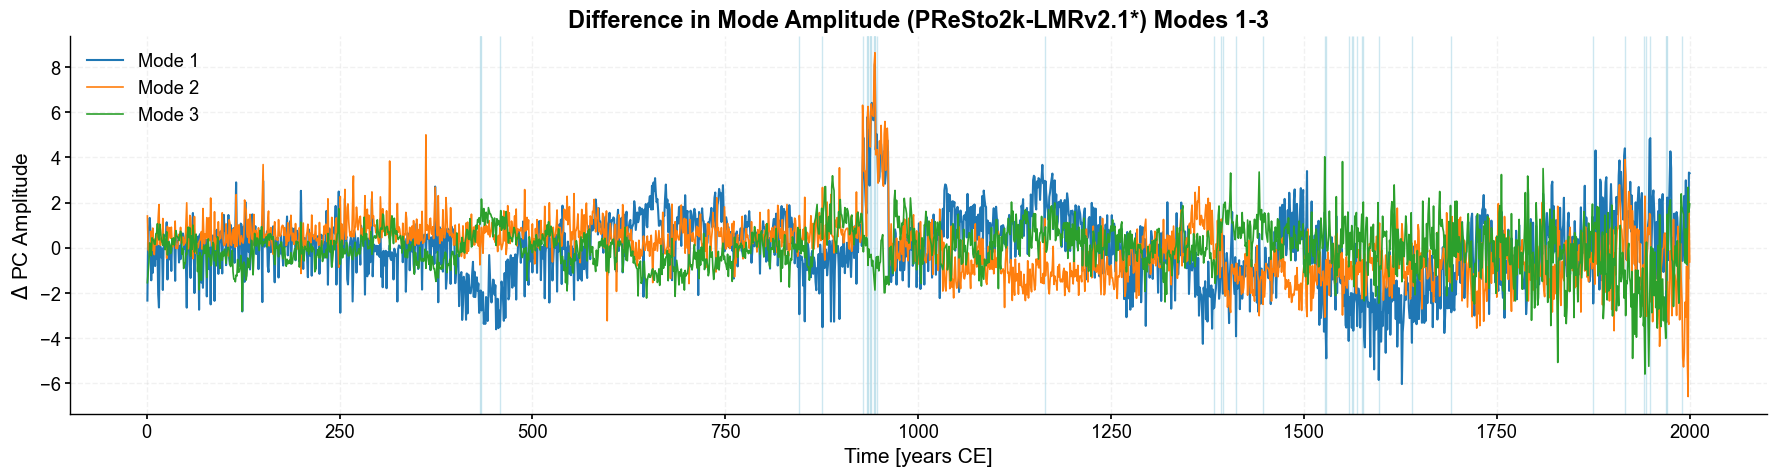

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Compute differences
diff_mode1 = scores_pc.sel(mode=1) - scores_lmr.sel(mode=1)
diff_mode2 = scores_pc.sel(mode=2) - scores_lmr.sel(mode=2)
diff_mode3 = scores_pc.sel(mode=3) - scores_lmr.sel(mode=3)

fig, ax = plt.subplots(figsize=(18, 5))

diff_mode1.plot(ax=ax, label="Mode 1", linewidth=1.5)
diff_mode2.plot(ax=ax, label="Mode 2", linewidth=1.2)
diff_mode3.plot(ax=ax, label="Mode 3", linewidth=1.2)

for start, end in intervals1:
    ax.axvspan(start, end, color='lightblue', alpha=0.6)

ax.set_title("Difference in Mode Amplitude (PReSto2k-LMRv2.1*) Modes 1-3", fontsize=17, fontweight='bold')
ax.set_ylabel(r"$\Delta$ PC Amplitude", fontsize=15)
ax.set_xlabel("Time [years CE]", fontsize=15)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


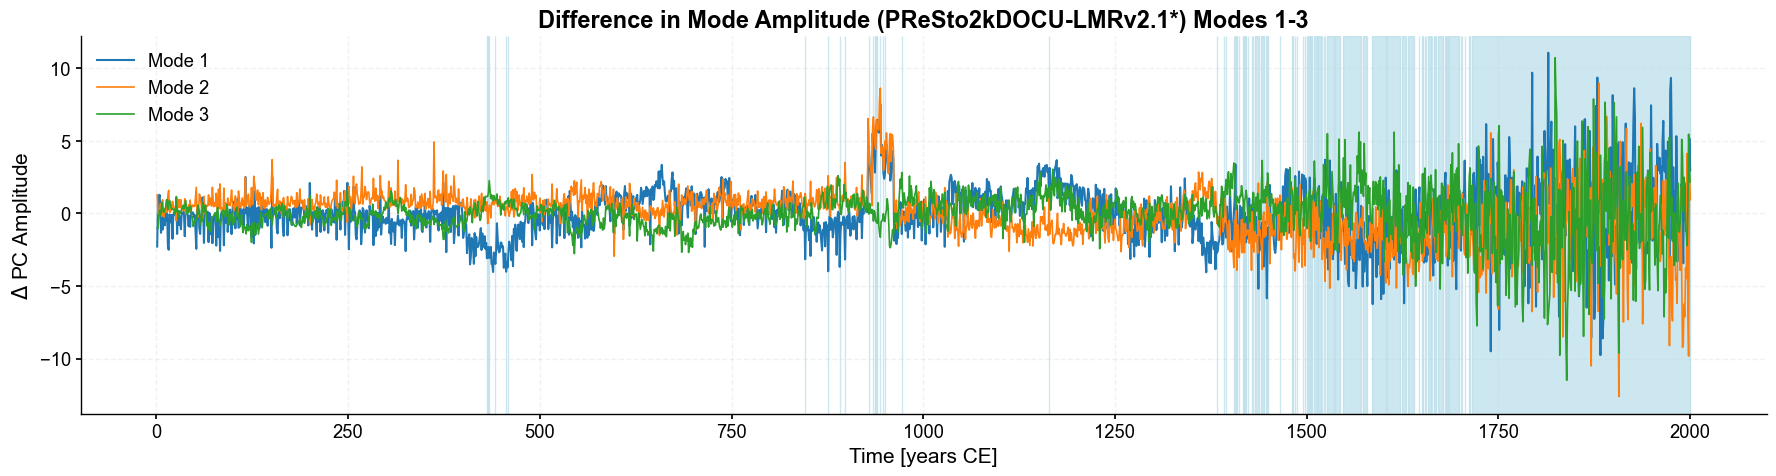

In [23]:
diff_mode1 = scores_dp.sel(mode=1) - scores_lmr.sel(mode=1)
diff_mode2 = scores_dp.sel(mode=2) - scores_lmr.sel(mode=2)
diff_mode3 = scores_dp.sel(mode=3) - scores_lmr.sel(mode=3)

fig, ax = plt.subplots(figsize=(18, 5))

diff_mode1.plot(ax=ax, label="Mode 1", linewidth=1.5)
diff_mode2.plot(ax=ax, label="Mode 2", linewidth=1.2)
diff_mode3.plot(ax=ax, label="Mode 3", linewidth=1.2)

for start, end in intervals2:
    ax.axvspan(start, end, color='lightblue', alpha=0.6)

ax.set_title("Difference in Mode Amplitude (PReSto2kDOCU-LMRv2.1*) Modes 1-3", fontsize=17, fontweight='bold')
ax.set_ylabel(r"$\Delta$ PC Amplitude", fontsize=15)
ax.set_xlabel("Time [years CE]", fontsize=15)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

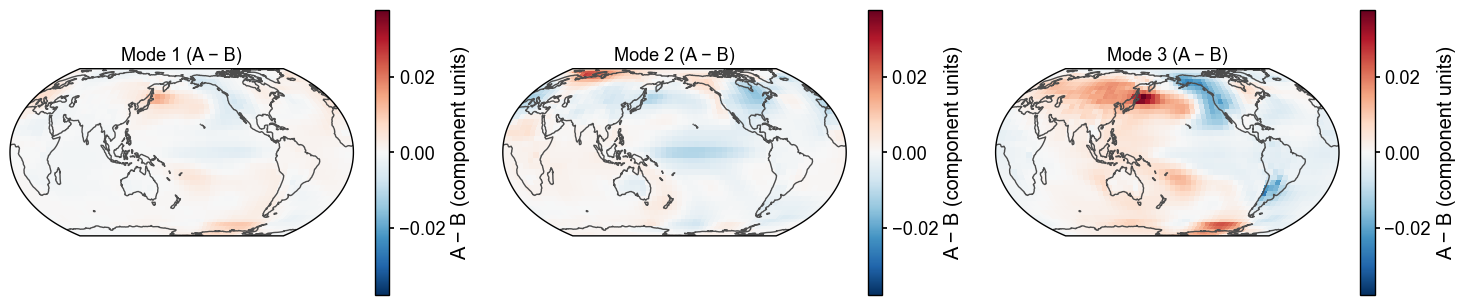

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# --- compute A − B field differences for the first 3 modes ---
diff_comp1 = components_pc.sel(mode=1) - components_lmr.sel(mode=1)
diff_comp2 = components_pc.sel(mode=2) - components_lmr.sel(mode=2)
diff_comp3 = components_pc.sel(mode=3) - components_lmr.sel(mode=3)

diffs = [diff_comp1, diff_comp2, diff_comp3]
titles = ["Mode 1 (PReSto2k − LMRv2.1*)", "Mode 2 (PReSto2k − LMRv2.1*)", "Mode 3 (PReSto2k − LMRv2.1*)"]

# shared symmetric color range across all three
vmax = max(float(np.abs(d).max()) for d in diffs)
vmin = -vmax

proj = ccrs.EqualEarth(central_longitude=180)
transform = ccrs.PlateCarree()

fig, axes = plt.subplots(
    nrows=1, ncols=3,
    figsize=(15, 4),                       # 3-panel figure
    subplot_kw={"projection": proj}
)

for ax, da, title in zip(axes, diffs, titles):
    im = da.plot(
        ax=ax,
        transform=transform,
        cmap="RdBu_r",
        vmin=vmin, vmax=vmax,
        add_colorbar=True,
        cbar_kwargs={"shrink": 0.8, "label": 'component unit'}
    )
    ax.coastlines(color=".3")
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


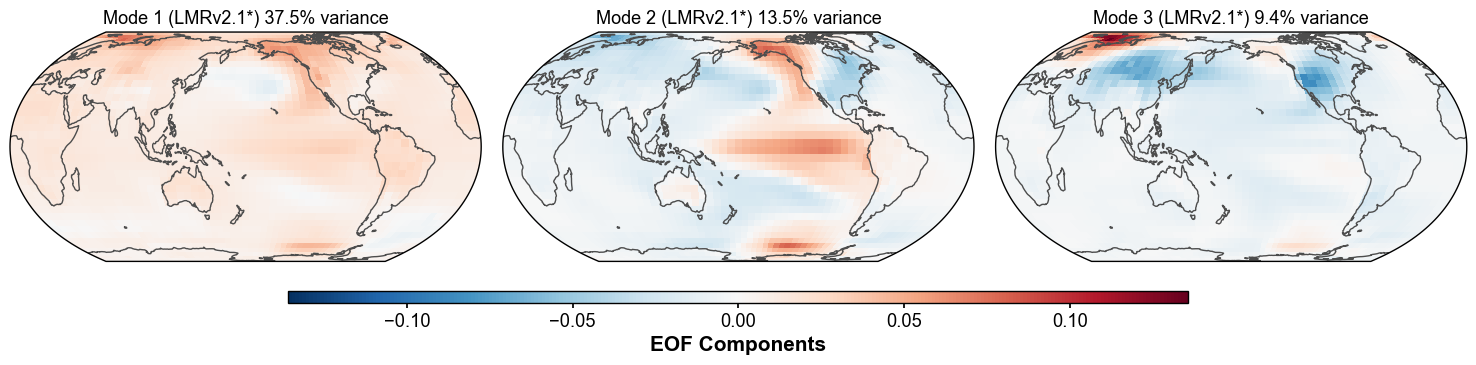

In [199]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# --- compute A − B field differences for the first 3 modes ---
diff_comp1 = components_lmr.sel(mode=1)
diff_comp2 = components_lmr.sel(mode=2)
diff_comp3 = components_lmr.sel(mode=3)

diffs = [diff_comp1, diff_comp2, diff_comp3]
titles = [f"Mode 1 (LMRv2.1*) {100*expvar_lmr[0]:3.1f}% variance",
          f"Mode 2 (LMRv2.1*) {100*expvar_lmr[1]:3.1f}% variance",
          f"Mode 3 (LMRv2.1*) {100*expvar_lmr[2]:3.1f}% variance"]

# shared symmetric color range
vmax = max(float(np.abs(d).max()) for d in diffs)
vmin = -vmax

proj = ccrs.EqualEarth(central_longitude=180)
transform = ccrs.PlateCarree()

fig, axes = plt.subplots(
    nrows=1, ncols=3,
    figsize=(15, 4),
    subplot_kw={"projection": proj}
)

mappable = None
for ax, da, title in zip(axes, diffs, titles):
    im = da.plot(
        ax=ax,
        transform=transform,
        cmap="RdBu_r",
        vmin=vmin, vmax=vmax,
        add_colorbar=False      # ← no per-panel colorbar
    )
    mappable = im              # keep one for the colorbar

    ax.coastlines(color=".3")
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Let tight_layout arrange the maps, but leave some room at the bottom
plt.tight_layout(rect=[0, 0.08, 1, 1])   # bottom margin = 0.08 of fig height



# [left, bottom, width, height] in figure coordinates (0–1)
cax = fig.add_axes([0.2, 0.15, 0.6, 0.03])

cbar = fig.colorbar(
    mappable,
    cax=cax,
    orientation="horizontal",
)
cbar.set_label('EOF Components', fontsize=15, fontweight='bold')  # Add label with optional fontsize

plt.show()



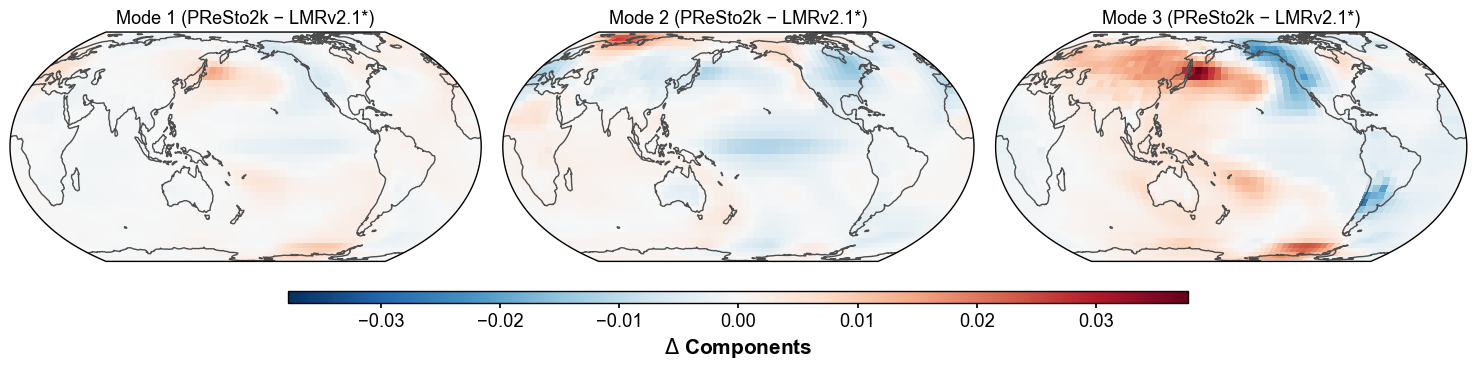

In [200]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# --- compute A − B field differences for the first 3 modes ---
diff_comp1 = components_pc.sel(mode=1) - components_lmr.sel(mode=1)
diff_comp2 = components_pc.sel(mode=2) - components_lmr.sel(mode=2)
diff_comp3 = components_pc.sel(mode=3) - components_lmr.sel(mode=3)

diffs = [diff_comp1, diff_comp2, diff_comp3]
titles = ["Mode 1 (PReSto2k − LMRv2.1*)",
          "Mode 2 (PReSto2k − LMRv2.1*)",
          "Mode 3 (PReSto2k − LMRv2.1*)"]

# shared symmetric color range
vmax = max(float(np.abs(d).max()) for d in diffs)
vmin = -vmax

proj = ccrs.EqualEarth(central_longitude=180)
transform = ccrs.PlateCarree()

fig, axes = plt.subplots(
    nrows=1, ncols=3,
    figsize=(15, 4),
    subplot_kw={"projection": proj}
)

mappable = None
for ax, da, title in zip(axes, diffs, titles):
    im = da.plot(
        ax=ax,
        transform=transform,
        cmap="RdBu_r",
        vmin=vmin, vmax=vmax,
        add_colorbar=False      # ← no per-panel colorbar
    )
    mappable = im              # keep one for the colorbar

    ax.coastlines(color=".3")
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Let tight_layout arrange the maps, but leave some room at the bottom
plt.tight_layout(rect=[0, 0.08, 1, 1])   # bottom margin = 0.08 of fig height



# [left, bottom, width, height] in figure coordinates (0–1)
cax = fig.add_axes([0.2, 0.15, 0.6, 0.03])

cbar = fig.colorbar(
    mappable,
    cax=cax,
    orientation="horizontal",
)
cbar.set_label(r'$\Delta$ Components', fontsize=15, fontweight='bold')  # Add label with optional fontsize

plt.show()



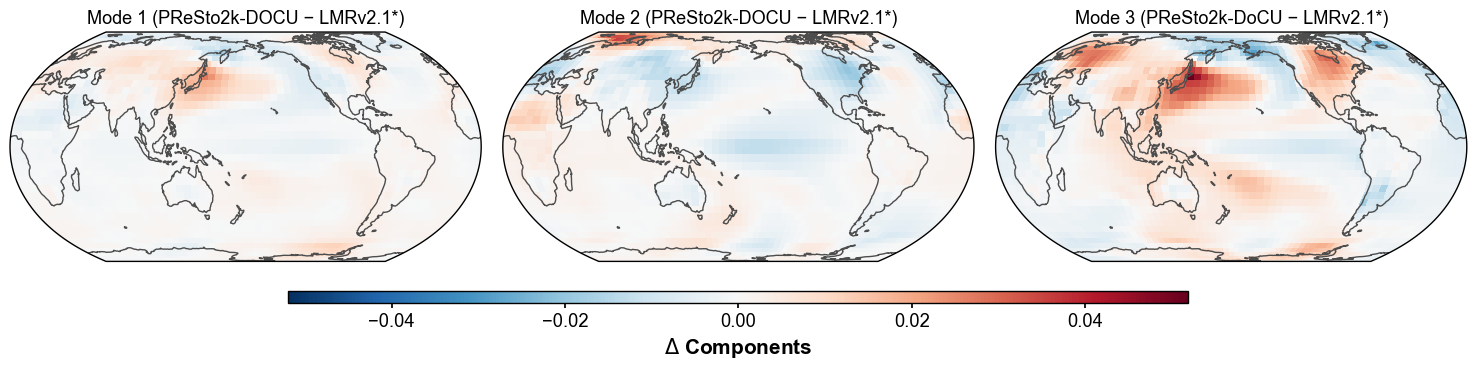

In [201]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# --- compute A − B field differences for the first 3 modes ---
diff_comp1 = components_dp.sel(mode=1) - components_lmr.sel(mode=1)
diff_comp2 = components_dp.sel(mode=2) - components_lmr.sel(mode=2)
diff_comp3 = components_dp.sel(mode=3) - components_lmr.sel(mode=3)

diffs = [diff_comp1, diff_comp2, diff_comp3]
titles = ["Mode 1 (PReSto2k-DOCU − LMRv2.1*)",
          "Mode 2 (PReSto2k-DOCU − LMRv2.1*)",
          "Mode 3 (PReSto2k-DoCU − LMRv2.1*)"]

# shared symmetric color range
vmax = max(float(np.abs(d).max()) for d in diffs)
vmin = -vmax

proj = ccrs.EqualEarth(central_longitude=180)
transform = ccrs.PlateCarree()

fig, axes = plt.subplots(
    nrows=1, ncols=3,
    figsize=(15, 4),
    subplot_kw={"projection": proj}
)

mappable = None
for ax, da, title in zip(axes, diffs, titles):
    im = da.plot(
        ax=ax,
        transform=transform,
        cmap="RdBu_r",
        vmin=vmin, vmax=vmax,
        add_colorbar=False      # ← no per-panel colorbar
    )
    mappable = im              # keep one for the colorbar

    ax.coastlines(color=".3")
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Let tight_layout arrange the maps, but leave some room at the bottom
plt.tight_layout(rect=[0, 0.08, 1, 1])   # bottom margin = 0.08 of fig height

# [left, bottom, width, height] in figure coordinates (0–1)
cax = fig.add_axes([0.2, 0.15, 0.6, 0.03])

cbar = fig.colorbar(
    mappable,
    cax=cax,
    orientation="horizontal",
)
cbar.set_label(r'$\Delta$ Components', fontsize=15, fontweight='bold')  # Add label with optional fontsize

plt.show()

